# TP 0 · Explorer AI4I 2020

Dataset de **maintenance prédictive** : 10 000 cycles de machines, avec leurs mesures et une colonne qui dit si la machine est tombée en panne.

**Objectif :** comprendre les données *avant* de faire du ML.
1. Charger le CSV et repérer les six features autorisées
2. Mesurer le taux de panne et les effectifs par Type
3. Comparer les taux par Type et représenter le torque
4. Rédiger deux constats et une limite du dataset

## 0. Setup

`TARGET` = ce qu'on veut prédire. `FEATURES` = les colonnes qu'on a le **droit** d'utiliser pour le prédire.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

TARGET = "Machine failure"
FEATURES = ["Torque [Nm]", "Type", "Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Tool wear [min]"]
df = pd.read_csv("data/ai4i2020.csv")

**Pourquoi seulement ces 6 features ?** Le dataset a 14 colonnes, mais on les trie en trois groupes :

| Groupe | Colonnes | Pourquoi |
|---|---|---|
| **Features autorisées** | Type, Air temperature, Process temperature, Rotational speed, Torque, Tool wear | Des mesures connues *avant* la panne → utilisables pour prédire |
| **Identifiants** | UDI, Product ID | Juste un numéro de ligne / de produit, aucune info physique (comme un numéro étudiant) |
| **Fuite (leakage)** | TWF, HDF, PWF, OSF, RNF | Ce sont les *types* de panne : connus seulement **après** la panne. Les utiliser = tricher |

## 1. Charger et regarder le dataset

Premier réflexe : regarder quelques lignes, les dimensions, les colonnes et leurs types.

In [2]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.shape

(10000, 14)

In [4]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [6]:
df.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

**Lecture :** 10 000 lignes, 14 colonnes, **aucune valeur manquante** → pas de nettoyage à faire. `Type` et `Product ID` sont du texte, le reste est numérique.

In [7]:
df.head(30)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0


## 2. Taux de panne global

`Machine failure` vaut 0 ou 1, donc sa **moyenne** = la proportion de pannes, et sa **somme** = le nombre de pannes.

In [8]:
df["Machine failure"].mean()

np.float64(0.0339)

In [9]:
df["Machine failure"].sum()

np.int64(339)

**Lecture :** **3,39 %** de pannes (339 sur 10 000). C'est une **classe rare** : un modèle qui répond toujours « pas de panne » aurait déjà 96,6 % de bonnes réponses. On s'en souviendra au TP 3.

## 3. Taux de panne par Type

`Type` = qualité du produit : **L** (low), **M** (medium), **H** (high). `groupby` découpe le dataset par Type, puis on calcule sur chaque groupe.

In [10]:
df.groupby("Type")["Machine failure"].mean()

Type
H    0.020937
L    0.039167
M    0.027694
Name: Machine failure, dtype: float64

In [11]:
df.groupby("Type")["Machine failure"].agg(["count", "sum", "mean"])

,count,sum,mean
Type,,,
H,1003,21,0.020937
L,6000,235,0.039167
M,2997,83,0.027694


**Lecture :**

| Type | Lignes | Pannes | Taux |
|---|---|---|---|
| L | 6000 | 235 | 3,9 % |
| M | 2997 | 83 | 2,8 % |
| H | 1003 | 21 | 2,1 % |

L a le plus de lignes **et** le taux le plus élevé. ⚠️ Il faut comparer les **taux**, pas les nombres de pannes : L a forcément plus de pannes puisqu'il a 6× plus de lignes que H.

In [12]:
taux = df.groupby("Type")["Machine failure"].mean() * 100

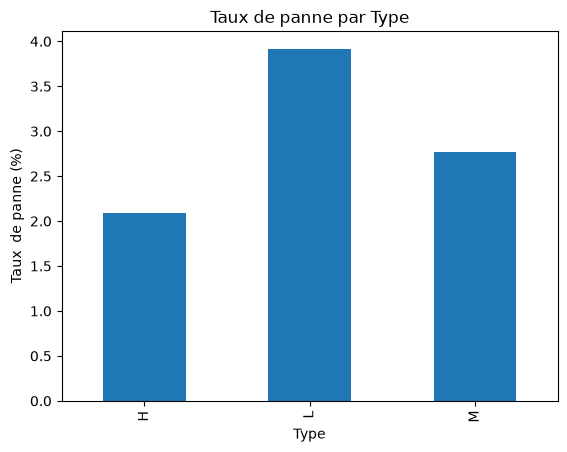

In [13]:
taux.plot(kind="bar")
plt.ylabel("Taux  de panne (%)")
plt.title("Taux de panne par Type")
plt.show()

**Lecture :** plus la qualité baisse (H → M → L), plus le taux de panne monte. Mais H n'a que 21 pannes : avec si peu d'exemples, son taux est **moins fiable** (il pourrait bouger beaucoup avec quelques pannes de plus ou de moins).

## 4. Le torque selon panne / pas panne

On compare la distribution du torque (couple) chez les machines saines (0) et en panne (1).

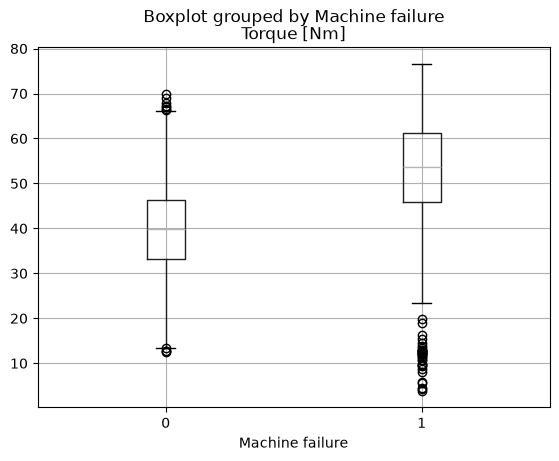

In [14]:
df.boxplot(column="Torque [Nm]", by="Machine failure")
plt.show()

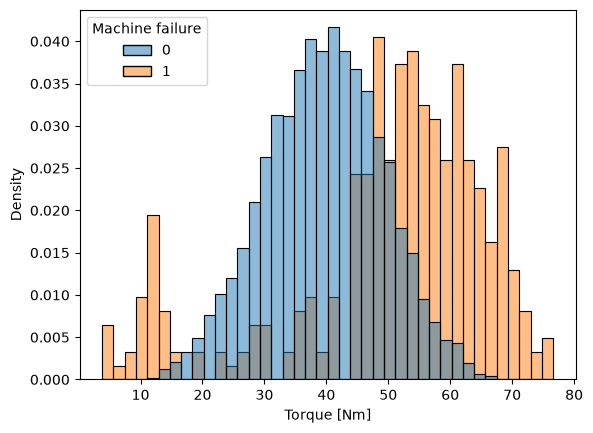

In [15]:
import seaborn as sns
sns.histplot(data=df, x="Torque [Nm]", hue="Machine failure", stat="density", common_norm=False, bins=40)
plt.show()

**Lecture :** les machines saines ont un torque autour de **30–50 Nm** (médiane ≈ 40). Les pannes sont décalées vers **45–60 Nm et au-delà** (médiane ≈ 54). Il y a aussi quelques pannes à **très bas torque** (min 3,8 Nm) : les deux extrêmes sont risqués.

`common_norm=False` normalise chaque groupe séparément : sans ça, les 339 pannes seraient écrasées par les 9661 lignes saines et invisibles sur le graphe.

## 5. Constats et limite

- **Constat 1 :** les pannes sont rares (3,39 %) → il faudra des métriques adaptées, pas l'accuracy.
- **Constat 2 :** le torque est nettement plus élevé (ou parfois très bas) quand il y a panne → c'est une feature prometteuse.
- **Limite :** classes déséquilibrées et peu de pannes par Type (21 pour H) → les taux par groupe sont incertains. De plus, c'est un dataset **synthétique** : les résultats ne se transposent pas forcément à de vraies machines.